In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [31]:
df = pd.read_csv('./data_2.csv')

In [32]:
print(df.head())

  Student_ID  Study_Hours  Attendance  Assignment_Score  Internal_Marks  \
0       S001          5.3        73.4              49.6            61.4   
1       S002          2.9        95.5              60.9            73.3   
2       S003          6.2        64.7              78.2            55.3   
3       S004          6.5        67.3              79.3            62.9   
4       S005          NaN        85.7              75.9            40.1   

   Final_Score  
0         37.3  
1         68.7  
2         65.5  
3         65.2  
4         56.1  


In [33]:
df.drop_duplicates()
df = df.fillna(df.mean(numeric_only=True))

In [34]:
X = df[['Study_Hours']]
Y = df['Final_Score']

In [35]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20
)
model = LinearRegression()
model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.15]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Study_Hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,55.76
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [36]:
Y_pred = model.predict(X_test)
print("MSE:", mean_squared_error(Y_test, Y_pred))
print("R-squared:", r2_score(Y_test, Y_pred))

MSE: 73.83800722830509
R-squared: -0.011532534068737776


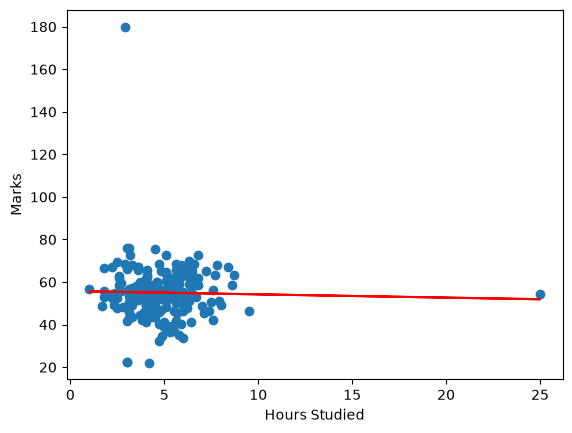

In [38]:
plt.scatter(X, Y)
plt.plot(X, model.predict(X), color='red')
plt.xlabel("Hours Studied")
plt.ylabel("Marks")
plt.show()